# Module 6: Cross-Dataset Analysis

## 6.0 · Setup

In [ ]:
PROJECT_DIR = "CounterShield"
SEED = 42
N_BOOT = 500
ADV_SAMPLE = 50_000
TRANSFER_TRAIN_CAP = 300_000
SHARED_FEATURES = ["dur", "spkts", "dpkts", "sbytes", "dbytes", "rate", "proto", "state"]

from google.colab import drive
drive.mount("/content/drive")
import sys, warnings, datetime as dt
warnings.filterwarnings("ignore", category=UserWarning)
try:
    from IPython.display import display
except ImportError:
    display = print
import matplotlib.pyplot as plt

import os, gc, json, time, re, hashlib
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score,
                             matthews_corrcoef, roc_auc_score, average_precision_score, confusion_matrix,
                             roc_curve, precision_recall_curve)

DATASETS = ["bot_iot", "cic_ids2017", "unsw_nb15"]
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e8e7e2"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]
MODEL_COLOR = {"classical": SERIES[0], "mlp": SERIES[1], "ensemble": SERIES[2]}

def sha256_file(path, block=8 * 1024 * 1024):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(block), b""):
            h.update(chunk)
    return h.hexdigest()

def _strat(y):
    y = pd.Series(y).astype(str); vc = y.value_counts()
    return y.where(~y.isin(vc.index[vc < 4]), "__rare__").to_numpy()

def load_split(base, m3, key, split, cap=None, seed=42, with_features=True):
    info = m3["datasets"][key]; feats = info["feature_names"]
    cols = (feats if with_features else []) + ["y_binary", "y_class", "row"]
    d = pd.read_parquet(base / info["files"][split]["path"], columns=cols)
    if cap and len(d) > cap:
        keep, _ = train_test_split(np.arange(len(d)), train_size=cap, stratify=_strat(d["y_class"]), random_state=seed)
        d = d.iloc[np.sort(keep)].reset_index(drop=True)
    X = d[feats].to_numpy(dtype=np.float32) if with_features else None
    return X, d["y_binary"].to_numpy().astype(int), d["y_class"].astype(str).to_numpy(), d["row"].to_numpy()

def label_family(c):
    if c == "benign": return "benign"
    if "ddos" in c: return "ddos"
    if "dos" in c: return "dos"
    if any(k in c for k in ("portscan", "reconnaissance", "recon", "scan", "fingerprint", "analysis")): return "recon"
    if any(k in c for k in ("patator", "brute", "password")) and "web" not in c: return "brute_force"
    if any(k in c for k in ("web_attack", "xss", "sql")): return "web_attack"
    if c in ("bot", "botnet"): return "botnet"
    if any(k in c for k in ("theft", "exfiltration", "keylog")): return "exfiltration_theft"
    if any(k in c for k in ("backdoor", "worm")): return "malware_backdoor"
    if any(k in c for k in ("exploit", "shellcode", "infiltration", "heartbleed")): return "exploit"
    return "other"

def binary_metrics(y, prob, thr=0.5):
    pred = (prob >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    both = len(np.unique(y)) == 2
    return {"threshold": float(thr), "accuracy": accuracy_score(y, pred), "balanced_accuracy": balanced_accuracy_score(y, pred),
            "precision_attack": precision_score(y, pred, zero_division=0), "recall_attack": recall_score(y, pred, zero_division=0),
            "f1_attack": f1_score(y, pred, zero_division=0), "f1_macro": f1_score(y, pred, average="macro", zero_division=0),
            "mcc": matthews_corrcoef(y, pred), "roc_auc": roc_auc_score(y, prob) if both else np.nan,
            "pr_auc": average_precision_score(y, prob) if both else np.nan,
            "fpr": fp / max(fp + tn, 1), "fnr": fn / max(fn + tp, 1), "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)}

def _counts_metrics(y, p):
    tp = (y & p).sum(-1); fp = (~y & p).sum(-1); fn = (y & ~p).sum(-1); tn = (~y & ~p).sum(-1)
    prec = tp / np.maximum(tp + fp, 1); rec = tp / np.maximum(tp + fn, 1)
    f1a = 2 * tp / np.maximum(2 * tp + fp + fn, 1); f1b = 2 * tn / np.maximum(2 * tn + fn + fp, 1)
    return {"precision_attack": prec, "recall_attack": rec, "f1_attack": f1a, "f1_macro": (f1a + f1b) / 2,
            "fpr": fp / np.maximum(fp + tn, 1), "fnr": fn / np.maximum(fn + tp, 1)}

def bootstrap_ci(y, pred, n_boot=500, seed=42, chunk=20):
    rng = np.random.default_rng(seed)
    y, pred = y.astype(bool), pred.astype(bool)
    n, acc = len(y), {}
    for s in range(0, n_boot, chunk):
        idx = rng.integers(0, n, size=(min(chunk, n_boot - s), n))
        for k, v in _counts_metrics(y[idx], pred[idx]).items():
            acc.setdefault(k, []).append(v)
    return {k: (float(np.percentile(np.concatenate(v), 2.5)), float(np.percentile(np.concatenate(v), 97.5))) for k, v in acc.items()}

def tune_threshold(y, prob, metric="f1_macro"):
    grid = np.unique(np.concatenate([np.linspace(0.01, 0.99, 99), np.quantile(prob, np.linspace(0.01, 0.99, 99))]))
    yb = y.astype(bool)
    P = prob[None, :] >= grid[:, None]
    scores = _counts_metrics(np.broadcast_to(yb, P.shape), P)[metric] if metric in ("f1_macro", "f1_attack") else None
    i = int(np.lexsort((np.abs(grid - 0.5), -scores))[0])
    return float(grid[i]), float(scores[i])

def threshold_for_fpr(y, prob, target):
    pb = np.sort(prob[y == 0])
    if len(pb) == 0: return 0.5
    k = int(np.floor(target * len(pb)))
    t = pb[len(pb) - k - 1] if k < len(pb) else pb[0]
    return float(np.nextafter(t, np.inf))

def per_class_detection(y_class, y, prob, thr):
    pred = (prob >= thr).astype(int)
    g = pd.DataFrame({"y_class": y_class, "y": y, "pred": pred}).groupby("y_class") \
          .agg(rows=("y", "size"), is_attack=("y", "max"), flagged=("pred", "mean")).reset_index()
    g["detection_rate"] = np.where(g.is_attack == 1, g.flagged, np.nan)
    g["false_alarm_rate"] = np.where(g.is_attack == 0, g.flagged, np.nan)
    return g.drop(columns="flagged")

def style_axes(ax):
    ax.grid(color=GRID, linewidth=0.8); ax.set_axisbelow(True); ax.tick_params(colors=MUTED, labelsize=8.5, length=0)
    for s in ax.spines.values(): s.set_visible(False)

def load_predictions(base):
    m4 = json.loads((base / "results/module4/model_selection.json").read_text())
    m5 = json.loads((base / "results/module5/experiment_selection.json").read_text())
    P, THR, NAMES = {}, {}, {}
    for k in DATASETS:
        a = pd.read_parquet(base / "results/module4/test_predictions" / f"{k}.parquet")
        b = pd.read_parquet(base / "results/module5/test_predictions" / f"{k}.parquet")
        assert (a.row.values == b.row.values).all(), f"{k}: Module 4 and Module 5 test rows differ"
        P[k] = pd.DataFrame({"row": a.row.values, "y_binary": a.y_binary.values.astype(int), "y_class": a.y_class.astype(str).values,
                             "p_classical": a.prob_attack.values.astype(np.float32), "p_mlp": b.prob_attack.values.astype(np.float32)})
        P[k]["y_family"] = P[k].y_class.map(label_family)
        THR[k] = {"classical": m4[k]["tuned_threshold"], "mlp": m5[k]["tuned_threshold"]}
        NAMES[k] = {"classical": m4[k]["model"], "mlp": "torch_" + m5[k]["experiment"]}
    return P, THR, NAMES, m4, m5

BASE = Path("/content/drive/MyDrive") / PROJECT_DIR
RES  = BASE / "results" / "module6"
(RES / "figures").mkdir(parents=True, exist_ok=True)
M2 = json.loads((BASE / "results/module2/module2_manifest.json").read_text())
M3 = json.loads((BASE / "results/module3/module3_manifest.json").read_text())
PRED, THR, MODEL_NAME, M4SEL, M5SEL = load_predictions(BASE)
MODELS = ["classical", "mlp"]
for k in DATASETS:
    print(f"{k:<12} test rows {len(PRED[k]):>9,} | classical = {MODEL_NAME[k]['classical']} @ {THR[k]['classical']:.3f} | "
          f"MLP = {MODEL_NAME[k]['mlp']} @ {THR[k]['mlp']:.3f}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
bot_iot      test rows   135,589 | classical = random_forest @ 0.660 | MLP = torch_mlp_128_64 @ 0.020
cic_ids2017  test rows   329,790 | classical = hist_gb @ 0.790 | MLP = torch_mlp_128_64 @ 0.700
unsw_nb15    test rows    82,332 | classical = hist_gb @ 0.480 | MLP = torch_mlp_256_128_64 @ 0.500


## 6.1 · Dataset-wise performance comparison

In [ ]:
overview, perf = [], []
for k in DATASETS:
    d, m2, m3 = PRED[k], M2["datasets"][k], M3["datasets"][k]
    overview.append({"dataset": k, "clean_rows": m2["rows"], "input_features": m2["features"], "model_features": len(m3["feature_names"]),
                     "classes": m2["n_classes"], "attack_rate": m2["attack_rate"],
                     "train": m3["files"]["train"]["rows"], "val": m3["files"]["val"]["rows"], "test": m3["files"]["test"]["rows"],
                     "test_benign": int((d.y_binary == 0).sum()), "test_attack": int(d.y_binary.sum())})
    for m in MODELS:
        r = binary_metrics(d.y_binary.values, d[f"p_{m}"].values, THR[k][m]); r.update(dataset=k, model=m, name=MODEL_NAME[k][m]); perf.append(r)
overview = pd.DataFrame(overview); perf = pd.DataFrame(perf)
overview.to_csv(RES / "dataset_overview.csv", index=False); perf.to_csv(RES / "performance_by_dataset.csv", index=False)
display(overview)
cols = ["dataset", "model", "name", "f1_macro", "f1_attack", "precision_attack", "recall_attack", "mcc", "balanced_accuracy", "roc_auc", "pr_auc", "fpr", "fnr"]
display(perf[cols].style.format({c: "{:.4f}" for c in cols[3:]}).hide(axis="index"))

,dataset,clean_rows,input_features,model_features,classes,attack_rate,train,val,test,test_benign,test_attack
0,bot_iot,903922,20,46,5,0.9899,632744,135589,135589,1371,134218
1,cic_ids2017,2198595,69,69,15,0.1529,1539015,329790,329790,279362,50428
2,unsw_nb15,181600,42,81,10,0.5118,84377,14891,82332,37000,45332


dataset,model,name,f1_macro,f1_attack,precision_attack,recall_attack,mcc,balanced_accuracy,roc_auc,pr_auc,fpr,fnr
bot_iot,classical,random_forest,0.9978,1.0000,1.0000,0.9999,0.9956,0.9992,1.0000,1.0000,0.0015,0.0001
bot_iot,mlp,torch_mlp_128_64,0.9880,0.9998,0.9999,0.9997,0.9760,0.9925,0.9998,1.0000,0.0146,0.0003
cic_ids2017,classical,hist_gb,0.9985,0.9974,0.9973,0.9974,0.9969,0.9985,0.9999,0.9988,0.0005,0.0026
cic_ids2017,mlp,torch_mlp_128_64,0.9943,0.9904,0.9872,0.9935,0.9886,0.9956,0.9999,0.9995,0.0023,0.0065
unsw_nb15,classical,hist_gb,0.8544,0.8861,0.8089,0.9795,0.7345,0.8480,0.9775,0.9831,0.2835,0.0205
unsw_nb15,mlp,torch_mlp_256_128_64,0.8589,0.8896,0.8119,0.9838,0.7438,0.8523,0.9809,0.9860,0.2793,0.0162


## 6.2 · Attack / normal class analysis

Detection rate by attack family (benign row = specificity), classical model:


dataset,bot_iot,cic_ids2017,unsw_nb15
family,,,
benign,0.9985,0.9995,0.7165
botnet,NaN,0.6667,NaN
brute_force,NaN,0.9956,NaN
ddos,1.0000,0.9995,NaN
dos,1.0000,0.9991,0.9768
exfiltration_theft,0.9748,NaN,NaN
exploit,NaN,0.5714,0.9877
malware_backdoor,NaN,NaN,0.9856
other,NaN,NaN,0.9740


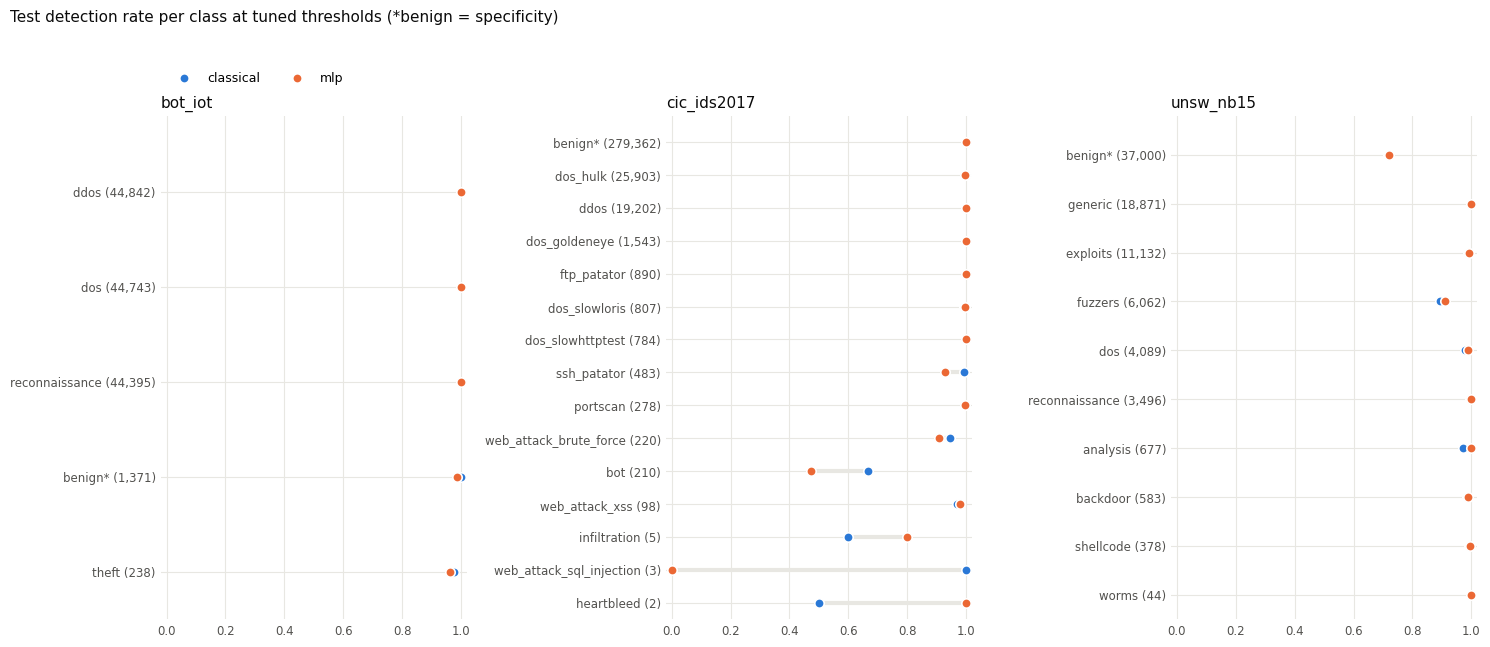

In [ ]:
pcs = []
for k in DATASETS:
    d = PRED[k]
    for m in MODELS:
        pc = per_class_detection(d.y_class.values, d.y_binary.values, d[f"p_{m}"].values, THR[k][m])
        pc.insert(0, "model", m); pc.insert(0, "dataset", k); pcs.append(pc)
per_class = pd.concat(pcs, ignore_index=True)
per_class["family"] = per_class.y_class.map(label_family)
per_class.to_csv(RES / "per_class_detection.csv", index=False)

fam = []
for k in DATASETS:
    d = PRED[k]
    for m in MODELS:
        pred = d[f"p_{m}"].values >= THR[k][m]
        g = pd.DataFrame({"family": d.y_family, "y": d.y_binary, "pred": pred}).groupby("family").agg(rows=("y", "size"), flagged=("pred", "mean"))
        for f, r in g.iterrows():
            fam.append({"dataset": k, "model": m, "family": f, "rows": int(r.rows),
                        "rate": r.flagged if f != "benign" else 1 - r.flagged})
family = pd.DataFrame(fam)
family.to_csv(RES / "family_detection.csv", index=False)
print("Detection rate by attack family (benign row = specificity), classical model:")
display(family[family.model == "classical"].pivot(index="family", columns="dataset", values="rate").round(4))

nmax = max(per_class[per_class.dataset == k].y_class.nunique() for k in DATASETS)
fig, axes = plt.subplots(1, len(DATASETS), figsize=(5.0 * len(DATASETS), 0.9 + 0.36 * nmax))
for ax, k in zip(axes, DATASETS):
    t = per_class[per_class.dataset == k].copy()
    t["score"] = np.where(t.is_attack == 1, t.detection_rate, 1 - t.false_alarm_rate)
    order = t[t.model == "classical"].sort_values("rows", ascending=False).y_class.tolist()
    for i, c in enumerate(order):
        a, b = [t[(t.model == m) & (t.y_class == c)].score.iloc[0] for m in MODELS]
        ax.hlines(i, min(a, b), max(a, b), color=GRID, linewidth=3, zorder=1)
        for m, v in zip(MODELS, (a, b)):
            ax.scatter(v, i, s=46, color=MODEL_COLOR[m], edgecolor="white", linewidth=1.2, zorder=3, label=m if i == 0 else None)
    n_rows = t[t.model == "classical"].set_index("y_class").rows
    ax.set_yticks(range(len(order))); ax.set_yticklabels([f"{c} ({n_rows[c]:,})" if c != "benign" else f"benign* ({n_rows[c]:,})" for c in order], fontsize=8, color=INK)
    ax.set_ylim(len(order) - 0.5, -0.8); ax.set_xlim(-0.02, 1.02); style_axes(ax); ax.set_title(k, loc="left", fontsize=11, color=INK)
axes[0].legend(frameon=False, fontsize=9, loc="lower left", ncol=2, bbox_to_anchor=(0, 1.04))
fig.suptitle("Test detection rate per class at tuned thresholds (*benign = specificity)", x=0.01, ha="left", fontsize=11, color=INK, y=1.02)
fig.tight_layout(); fig.savefig(RES / "figures" / "per_class_detection.png", dpi=200, bbox_inches="tight"); plt.show()

## 6.3 · Precision / recall / F1 comparison

In [ ]:
prf = []
for k in DATASETS:
    d = PRED[k]; y = d.y_binary.values
    for m in MODELS:
        pred = (d[f"p_{m}"].values >= THR[k][m])
        point = {kk: float(v[0]) for kk, v in _counts_metrics(y[None].astype(bool), pred[None]).items()}
        ci = bootstrap_ci(y, pred, N_BOOT, SEED)
        row = {"dataset": k, "model": m}
        for met in ["precision_attack", "recall_attack", "f1_attack", "f1_macro", "fpr", "fnr"]:
            row[met] = point[met]; row[met + "_lo"], row[met + "_hi"] = ci[met]
        prf.append(row)
prf = pd.DataFrame(prf); prf.to_csv(RES / "precision_recall_f1_ci.csv", index=False)
show = prf[["dataset", "model"]].copy()
for met in ["precision_attack", "recall_attack", "f1_attack", "f1_macro", "fpr"]:
    show[met] = [f"{r[met]:.4f} [{r[met + '_lo']:.4f}, {r[met + '_hi']:.4f}]" for _, r in prf.iterrows()]
display(show)

,dataset,model,precision_attack,recall_attack,f1_attack,f1_macro,fpr
0,bot_iot,classical,"1.0000 [1.0000, 1.0000]","0.9999 [0.9999, 1.0000]","1.0000 [0.9999, 1.0000]","0.9978 [0.9964, 0.9989]","0.0015 [0.0000, 0.0037]"
1,bot_iot,mlp,"0.9999 [0.9998, 0.9999]","0.9997 [0.9996, 0.9998]","0.9998 [0.9997, 0.9998]","0.9880 [0.9848, 0.9907]","0.0146 [0.0088, 0.0208]"
2,cic_ids2017,classical,"0.9973 [0.9969, 0.9978]","0.9974 [0.9970, 0.9979]","0.9974 [0.9971, 0.9977]","0.9985 [0.9983, 0.9986]","0.0005 [0.0004, 0.0006]"
3,cic_ids2017,mlp,"0.9872 [0.9862, 0.9880]","0.9935 [0.9928, 0.9943]","0.9904 [0.9897, 0.9909]","0.9943 [0.9939, 0.9946]","0.0023 [0.0022, 0.0025]"
4,unsw_nb15,classical,"0.8089 [0.8054, 0.8123]","0.9795 [0.9782, 0.9807]","0.8861 [0.8839, 0.8882]","0.8544 [0.8521, 0.8569]","0.2835 [0.2790, 0.2878]"
5,unsw_nb15,mlp,"0.8119 [0.8084, 0.8149]","0.9838 [0.9826, 0.9849]","0.8896 [0.8875, 0.8915]","0.8589 [0.8566, 0.8614]","0.2793 [0.2750, 0.2834]"


## 6.4 · ROC-AUC and PR-AUC comparison

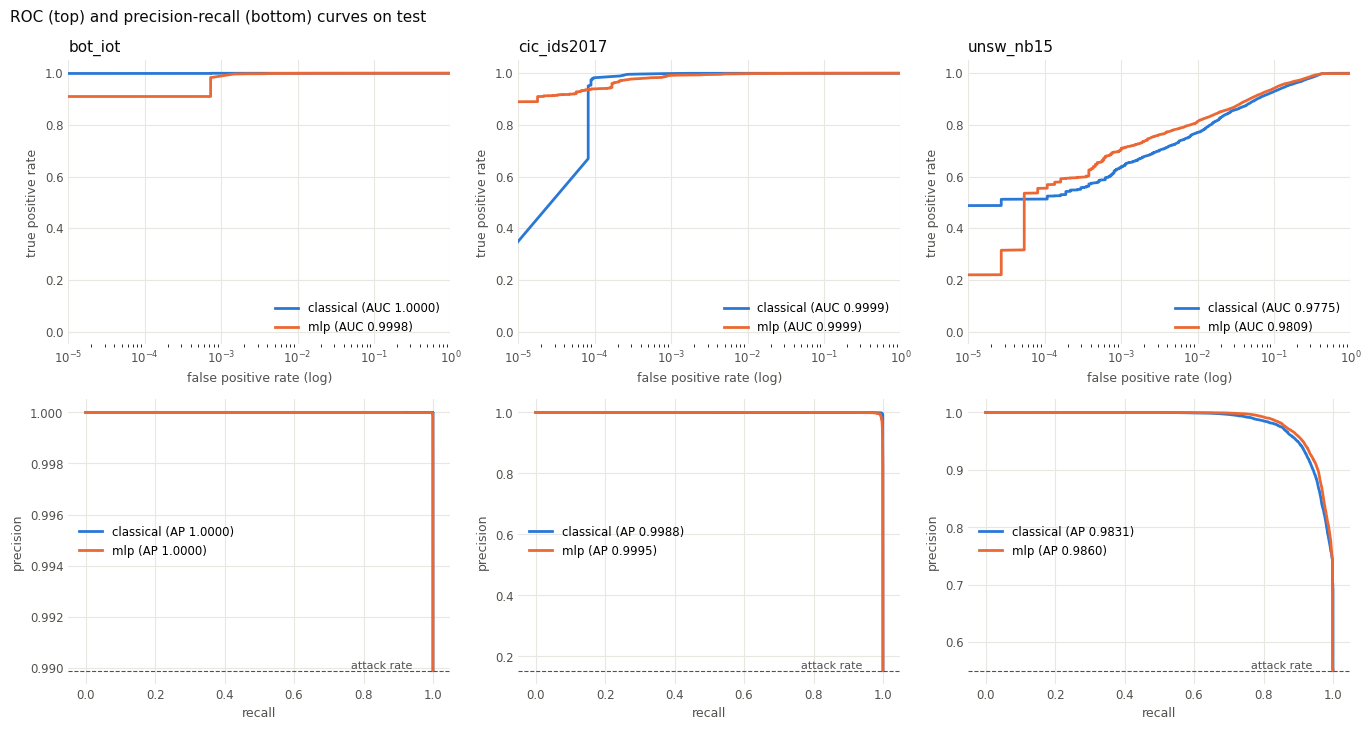

,dataset,model,roc_auc,pauc_fpr_1pct,pr_auc,pr_baseline
0,bot_iot,classical,1.00000,0.99996,1.00000,0.98989
1,bot_iot,mlp,0.99983,0.99612,1.00000,0.98989
2,cic_ids2017,classical,0.99986,0.99556,0.99881,0.15291
3,cic_ids2017,mlp,0.99988,0.99697,0.99950,0.15291
4,unsw_nb15,classical,0.97749,0.85452,0.98309,0.55060
5,unsw_nb15,mlp,0.98094,0.88050,0.98599,0.55060


In [ ]:
auc_rows = []
fig, axes = plt.subplots(2, len(DATASETS), figsize=(4.6 * len(DATASETS), 7.4))
for j, k in enumerate(DATASETS):
    d = PRED[k]; y = d.y_binary.values; prev = y.mean()
    for m in MODELS:
        p = d[f"p_{m}"].values
        fpr, tpr, _ = roc_curve(y, p); prec, rec, _ = precision_recall_curve(y, p)
        auc_rows.append({"dataset": k, "model": m, "roc_auc": roc_auc_score(y, p), "pauc_fpr_1pct": roc_auc_score(y, p, max_fpr=0.01),
                         "pr_auc": average_precision_score(y, p), "pr_baseline": prev})
        keep = np.unique(np.linspace(0, len(fpr) - 1, min(len(fpr), 3000)).astype(int))
        axes[0, j].plot(np.clip(fpr[keep], 1e-6, 1), tpr[keep], color=MODEL_COLOR[m], linewidth=2, label=f"{m} (AUC {auc_rows[-1]['roc_auc']:.4f})")
        keep = np.unique(np.linspace(0, len(rec) - 1, min(len(rec), 3000)).astype(int))
        axes[1, j].plot(rec[keep], prec[keep], color=MODEL_COLOR[m], linewidth=2, label=f"{m} (AP {auc_rows[-1]['pr_auc']:.4f})")
    axes[0, j].set_xscale("log"); axes[0, j].set_xlim(1e-5, 1); axes[0, j].set_title(k, loc="left", fontsize=11, color=INK)
    axes[0, j].set_xlabel("false positive rate (log)", color=MUTED, fontsize=9); axes[0, j].set_ylabel("true positive rate", color=MUTED, fontsize=9)
    axes[1, j].axhline(prev, color=MUTED, linewidth=0.8, linestyle="--"); axes[1, j].text(0.95, prev, "attack rate ", color=MUTED, fontsize=8, va="bottom", ha="right")
    axes[1, j].set_xlabel("recall", color=MUTED, fontsize=9); axes[1, j].set_ylabel("precision", color=MUTED, fontsize=9)
    for a in axes[:, j]:
        style_axes(a); a.legend(frameon=False, fontsize=8.5, loc="lower right" if a is axes[0, j] else "center left")
fig.suptitle("ROC (top) and precision-recall (bottom) curves on test", x=0.01, ha="left", fontsize=11, color=INK)
fig.tight_layout(); fig.savefig(RES / "figures" / "roc_pr_curves.png", dpi=200, bbox_inches="tight"); plt.show()
aucs = pd.DataFrame(auc_rows); aucs.to_csv(RES / "auc_comparison.csv", index=False)
display(aucs.round(5))

## 6.5 · Confusion-matrix analysis

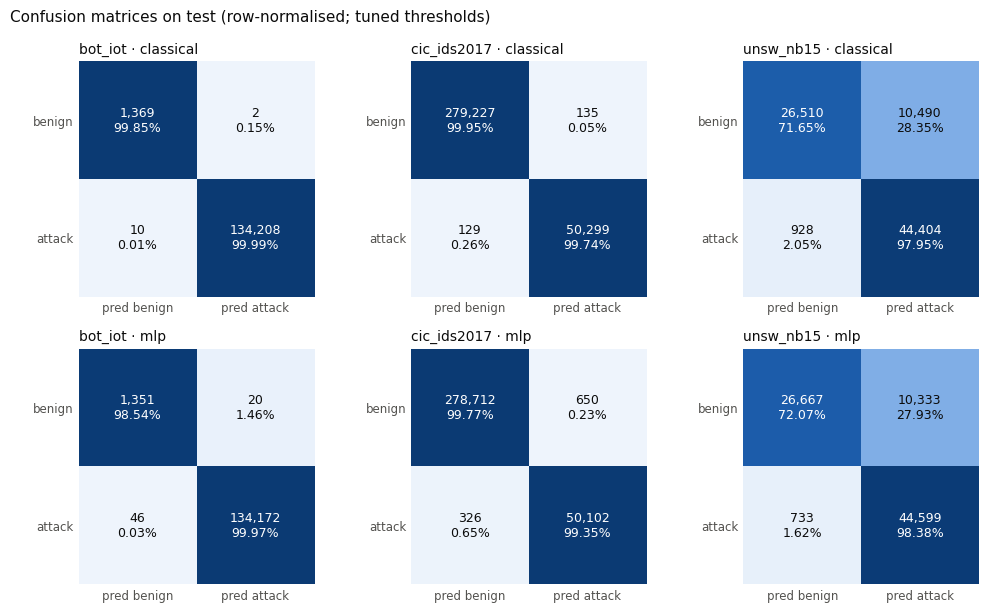

,dataset,model,tn,fp,fn,tp,tnr,fpr,fnr,tpr
0,bot_iot,classical,1369,2,10,134208,0.99854,0.00146,0.00007,0.99993
1,cic_ids2017,classical,279227,135,129,50299,0.99952,0.00048,0.00256,0.99744
2,unsw_nb15,classical,26510,10490,928,44404,0.71649,0.28351,0.02047,0.97953
3,bot_iot,mlp,1351,20,46,134172,0.98541,0.01459,0.00034,0.99966
4,cic_ids2017,mlp,278712,650,326,50102,0.99767,0.00233,0.00646,0.99354
5,unsw_nb15,mlp,26667,10333,733,44599,0.72073,0.27927,0.01617,0.98383


In [ ]:
cm_rows = []
fig, axes = plt.subplots(len(MODELS), len(DATASETS), figsize=(3.4 * len(DATASETS), 3.1 * len(MODELS)))
from matplotlib.colors import LinearSegmentedColormap
BLUES = LinearSegmentedColormap.from_list("seq", ["#eef4fc", "#2a78d6", "#0b3a73"])
for i, m in enumerate(MODELS):
    for j, k in enumerate(DATASETS):
        d = PRED[k]; y = d.y_binary.values; pred = (d[f"p_{m}"].values >= THR[k][m]).astype(int)
        cm = confusion_matrix(y, pred, labels=[0, 1]); cmn = cm / cm.sum(axis=1, keepdims=True)
        cm_rows.append({"dataset": k, "model": m, "tn": cm[0, 0], "fp": cm[0, 1], "fn": cm[1, 0], "tp": cm[1, 1],
                        "tnr": cmn[0, 0], "fpr": cmn[0, 1], "fnr": cmn[1, 0], "tpr": cmn[1, 1]})
        ax = axes[i, j]; ax.imshow(cmn, cmap=BLUES, vmin=0, vmax=1)
        for a in range(2):
            for b in range(2):
                ax.text(b, a, f"{cm[a, b]:,}\n{cmn[a, b]:.2%}", ha="center", va="center", fontsize=9,
                        color="white" if cmn[a, b] > 0.55 else INK)
        ax.set_xticks([0, 1]); ax.set_xticklabels(["pred benign", "pred attack"], fontsize=8.5, color=MUTED)
        ax.set_yticks([0, 1]); ax.set_yticklabels(["benign", "attack"], fontsize=8.5, color=MUTED)
        ax.tick_params(length=0)
        for s in ax.spines.values(): s.set_visible(False)
        ax.set_title(f"{k} · {m}", loc="left", fontsize=10, color=INK)
fig.suptitle("Confusion matrices on test (row-normalised; tuned thresholds)", x=0.01, ha="left", fontsize=11, color=INK)
fig.tight_layout(); fig.savefig(RES / "figures" / "confusion_matrices.png", dpi=200, bbox_inches="tight"); plt.show()
cms = pd.DataFrame(cm_rows); cms.to_csv(RES / "confusion_matrices.csv", index=False)
display(cms.round(5))

## 6.6 · Generalization analysis

In [ ]:
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
gap = []
for k in DATASETS:
    r = perf[perf.dataset == k].set_index("model")
    gap.append({"dataset": k, "model": "classical", "val_f1_macro": M4SEL[k]["val_f1_macro_at_tuned"], "test_f1_macro": r.loc["classical", "f1_macro"]})
    gap.append({"dataset": k, "model": "mlp", "val_f1_macro": M5SEL[k]["val_f1_macro_at_tuned"], "test_f1_macro": r.loc["mlp", "f1_macro"]})
gap = pd.DataFrame(gap); gap["gap"] = gap.test_f1_macro - gap.val_f1_macro
gap.to_csv(RES / "val_test_gap.csv", index=False); display(gap.round(4))

adv = []
for k in DATASETS:
    feats = M3["datasets"][k]["feature_names"]
    Xa, _, _, _ = load_split(BASE, M3, k, "train", cap=ADV_SAMPLE, seed=SEED)
    Xb, _, _, _ = load_split(BASE, M3, k, "test", cap=ADV_SAMPLE, seed=SEED)
    X = np.concatenate([Xa, Xb]); z = np.r_[np.zeros(len(Xa)), np.ones(len(Xb))].astype(int)
    Xtr, Xte, ztr, zte = train_test_split(X, z, test_size=0.3, stratify=z, random_state=SEED)
    rf = RandomForestClassifier(n_estimators=100, max_depth=14, n_jobs=-1, random_state=SEED).fit(Xtr, ztr)
    auc = roc_auc_score(zte, rf.predict_proba(Xte)[:, 1])
    top = pd.Series(rf.feature_importances_, index=feats).sort_values(ascending=False).head(5)
    adv.append({"dataset": k, "train_vs_test_auc": auc, "shift_level": "strong" if auc > 0.75 else ("moderate" if auc > 0.6 else "none/weak"),
                "top_shift_features": ", ".join(f"{f.split('__', 1)[-1]} ({v:.2f})" for f, v in top.items())})
    del X, Xa, Xb, rf; gc.collect()
adv = pd.DataFrame(adv); adv.to_csv(RES / "adversarial_validation.csv", index=False); display(adv)

TR_SETS = ["bot_iot", "unsw_nb15"]
clean = {k: pd.read_parquet(BASE / M2["datasets"][k]["output"]) for k in TR_SETS}
man = {k: pd.read_parquet(BASE / M3["datasets"][k]["split_manifest"]) for k in TR_SETS}
shared = [f for f in SHARED_FEATURES if all(f in clean[k].columns for k in TR_SETS)]
num_sh = [f for f in shared if f not in ("proto", "state")]; cat_sh = [f for f in shared if f in ("proto", "state")]
cat_levels = {c: sorted(set.intersection(*[set(clean[k][c].astype(str).str.lower().value_counts().head(8).index) for k in TR_SETS])) for c in cat_sh}
def shared_X(df):
    parts = [np.log1p(df[num_sh].astype("float64").clip(lower=0)).to_numpy()] if num_sh else []
    for c in cat_sh:
        v = df[c].astype(str).str.lower().to_numpy()
        parts.append(np.stack([(v == lv) for lv in cat_levels[c]] + [~np.isin(v, cat_levels[c])], axis=1).astype(float))
    return np.concatenate(parts, axis=1).astype(np.float32)
print("shared features:", num_sh, "| categorical:", {c: cat_levels[c] for c in cat_sh})
transfer = []
if len(shared) >= 2:
    for src in TR_SETS:
        tr_rows = man[src].loc[man[src].split == "train", "row"].to_numpy()
        if len(tr_rows) > TRANSFER_TRAIN_CAP:
            tr_rows, _ = train_test_split(tr_rows, train_size=TRANSFER_TRAIN_CAP, stratify=_strat(man[src].set_index("row").loc[tr_rows, "y_class"]), random_state=SEED)
        s = clean[src].iloc[tr_rows]
        mdl = HistGradientBoostingClassifier(max_iter=300, class_weight="balanced", random_state=SEED).fit(shared_X(s), s.y_binary.values)
        for tgt in TR_SETS:
            te_rows = man[tgt].loc[man[tgt].split == "test", "row"].to_numpy(); t = clean[tgt].iloc[te_rows]
            p = mdl.predict_proba(shared_X(t))[:, 1]; r = binary_metrics(t.y_binary.values, p, 0.5)
            transfer.append({"train_on": src, "test_on": tgt, "setting": "in-domain" if src == tgt else "cross-domain",
                             "f1_macro": r["f1_macro"], "roc_auc": r["roc_auc"], "pr_auc": r["pr_auc"], "fpr": r["fpr"], "fnr": r["fnr"],
                             "test_attack_rate": float(t.y_binary.mean())})
transfer = pd.DataFrame(transfer); transfer.to_csv(RES / "cross_dataset_transfer.csv", index=False)
display(transfer.round(4) if len(transfer) else "not enough shared features for transfer")
del clean; gc.collect()

,dataset,model,val_f1_macro,test_f1_macro,gap
0,bot_iot,classical,0.9978,0.9978,0.0000
1,bot_iot,mlp,0.9860,0.9880,0.0019
2,cic_ids2017,classical,0.9980,0.9985,0.0005
3,cic_ids2017,mlp,0.9964,0.9943,-0.0021
4,unsw_nb15,classical,0.9350,0.8544,-0.0805
5,unsw_nb15,mlp,0.9182,0.8589,-0.0593


,dataset,train_vs_test_auc,shift_level,top_shift_features
0,bot_iot,0.493762,none/weak,"sport (0.14), dur (0.10), rate (0.10), srate (..."
1,cic_ids2017,0.501718,none/weak,"Flow Duration (0.03), Fwd Packets/s (0.03), Fl..."
2,unsw_nb15,0.874172,strong,"ct_dst_sport_ltm (0.07), dbytes (0.06), sbytes..."


shared features: ['dur', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate'] | categorical: {'proto': ['arp', 'tcp', 'udp'], 'state': ['acc', 'con', 'eco', 'fin', 'int', 'req', 'rst']}


,train_on,test_on,setting,f1_macro,roc_auc,pr_auc,fpr,fnr,test_attack_rate
0,bot_iot,bot_iot,in-domain,0.9893,0.9996,1.0000,0.0080,0.0004,0.9899
1,bot_iot,unsw_nb15,cross-domain,0.3097,0.3458,0.4871,0.6901,0.6892,0.5506
2,unsw_nb15,bot_iot,cross-domain,0.2572,0.1489,0.9661,0.9555,0.6517,0.9899
3,unsw_nb15,unsw_nb15,in-domain,0.8467,0.9719,0.9784,0.2917,0.0271,0.5506


64

## 6.7 · Error analysis

In [ ]:
overlap, fn_cls, conf, drivers = [], [], [], []
for k in DATASETS:
    d = PRED[k]; y = d.y_binary.values.astype(bool)
    wrong = {m: (d[f"p_{m}"].values >= THR[k][m]) != y for m in MODELS}
    overlap.append({"dataset": k, "both_correct": int((~wrong["classical"] & ~wrong["mlp"]).sum()),
                    "only_classical_wrong": int((wrong["classical"] & ~wrong["mlp"]).sum()),
                    "only_mlp_wrong": int((~wrong["classical"] & wrong["mlp"]).sum()),
                    "both_wrong": int((wrong["classical"] & wrong["mlp"]).sum())})
    for m in MODELS:
        p = d[f"p_{m}"].values; t = THR[k][m]; err = wrong[m]
        fn = err & y
        g = pd.Series(d.y_class.values[fn]).value_counts()
        for c, n in g.items():
            fn_cls.append({"dataset": k, "model": m, "y_class": c, "false_negatives": int(n), "share_of_fn": n / max(fn.sum(), 1),
                           "class_miss_rate": n / int((d.y_class.values == c).sum())})
        near = err & (np.abs(p - t) <= 0.1); sure = err & ((p <= 0.05) | (p >= 0.95))
        conf.append({"dataset": k, "model": m, "errors": int(err.sum()), "borderline_within_0.1": int(near.sum()),
                     "confident_errors": int(sure.sum()), "pct_borderline": near.sum() / max(err.sum(), 1),
                     "pct_confident": sure.sum() / max(err.sum(), 1)})
    feats = M3["datasets"][k]["feature_names"]
    X, yy, _, rows = load_split(BASE, M3, k, "test")
    assert (rows == d.row.values).all()
    pc = d.p_classical.values >= THR[k]["classical"]
    for label, a_mask, b_mask in [("false_alarm_vs_true_negative", (~y) & pc, (~y) & ~pc), ("missed_vs_detected_attack", y & ~pc, y & pc)]:
        if a_mask.sum() >= 5 and b_mask.sum() >= 5:
            A, B = X[a_mask], X[b_mask]
            smd = (A.mean(0) - B.mean(0)) / np.sqrt((A.var(0) + B.var(0)) / 2 + 1e-9)
            for i in np.argsort(-np.abs(smd))[:6]:
                drivers.append({"dataset": k, "comparison": label, "feature": feats[i].split("__", 1)[-1], "std_mean_diff": float(smd[i]),
                                "n_error_rows": int(a_mask.sum())})
    del X; gc.collect()
overlap = pd.DataFrame(overlap); fn_cls = pd.DataFrame(fn_cls); conf = pd.DataFrame(conf); drivers = pd.DataFrame(drivers)
for n, t in [("error_overlap", overlap), ("false_negatives_by_class", fn_cls), ("error_confidence", conf), ("error_feature_drivers", drivers)]:
    t.to_csv(RES / f"{n}.csv", index=False)
print("Error overlap between classical and MLP:"); display(overlap)
print("\nMissed attacks by class (classical, top 5 per dataset):")
display(fn_cls[fn_cls.model == "classical"].sort_values(["dataset", "false_negatives"], ascending=[True, False]).groupby("dataset").head(5).round(4))
print("\nBorderline vs confident errors:"); display(conf.round(4))
print("\nFeatures that most separate errors from correct predictions (standardised mean difference, classical model):"); display(drivers.round(3))

Error overlap between classical and MLP:


,dataset,both_correct,only_classical_wrong,only_mlp_wrong,both_wrong
0,bot_iot,135518,5,59,7
1,cic_ids2017,328710,104,816,160
2,unsw_nb15,68936,2330,1978,9088



Missed attacks by class (classical, top 5 per dataset):


,dataset,model,y_class,false_negatives,share_of_fn,class_miss_rate
0,bot_iot,classical,theft,6,0.6000,0.0252
1,bot_iot,classical,reconnaissance,2,0.2000,0.0000
2,bot_iot,classical,dos,1,0.1000,0.0000
3,bot_iot,classical,ddos,1,0.1000,0.0000
8,cic_ids2017,classical,bot,70,0.5426,0.3333
9,cic_ids2017,classical,dos_hulk,18,0.1395,0.0007
10,cic_ids2017,classical,web_attack_brute_force,12,0.0930,0.0545
11,cic_ids2017,classical,ddos,9,0.0698,0.0005
12,cic_ids2017,classical,dos_slowloris,6,0.0465,0.0074
32,unsw_nb15,classical,fuzzers,641,0.6907,0.1057



Borderline vs confident errors:


,dataset,model,errors,borderline_within_0.1,confident_errors,pct_borderline,pct_confident
0,bot_iot,classical,12,2,3,0.1667,0.2500
1,bot_iot,mlp,66,54,52,0.8182,0.7879
2,cic_ids2017,classical,264,117,82,0.4432,0.3106
3,cic_ids2017,mlp,976,198,297,0.2029,0.3043
4,unsw_nb15,classical,11418,2231,925,0.1954,0.0810
5,unsw_nb15,mlp,11066,3853,703,0.3482,0.0635



Features that most separate errors from correct predictions (standardised mean difference, classical model):


,dataset,comparison,feature,std_mean_diff,n_error_rows
0,bot_iot,missed_vs_detected_attack,drate,2.196,10
1,bot_iot,missed_vs_detected_attack,state_con,2.157,10
2,bot_iot,missed_vs_detected_attack,dbytes,1.592,10
3,bot_iot,missed_vs_detected_attack,dpkts,1.582,10
4,bot_iot,missed_vs_detected_attack,spkts,1.063,10
5,bot_iot,missed_vs_detected_attack,sbytes,1.060,10
6,cic_ids2017,false_alarm_vs_true_negative,Fwd Packet Length Mean,-1.826,135
7,cic_ids2017,false_alarm_vs_true_negative,Avg Fwd Segment Size,-1.826,135
8,cic_ids2017,false_alarm_vs_true_negative,Subflow Fwd Bytes,-1.811,135
9,cic_ids2017,false_alarm_vs_true_negative,Total Length of Fwd Packets,-1.811,135


### Module 6 summary

In [ ]:
lines = ["# Module 6 — Cross-dataset analysis", "", "## Test performance (tuned thresholds)", "",
         "| Dataset | Model | Macro-F1 [95% CI] | Precision | Recall | ROC-AUC | pAUC@1% | PR-AUC | FPR | FNR |", "|---|---|---|---|---|---|---|---|---|---|"]
for k in DATASETS:
    for m in MODELS:
        r = prf[(prf.dataset == k) & (prf.model == m)].iloc[0]; a = aucs[(aucs.dataset == k) & (aucs.model == m)].iloc[0]
        lines.append(f"| {k} | {MODEL_NAME[k][m]} | {r.f1_macro:.4f} [{r.f1_macro_lo:.4f}, {r.f1_macro_hi:.4f}] | {r.precision_attack:.4f} | "
                     f"{r.recall_attack:.4f} | {a.roc_auc:.4f} | {a.pauc_fpr_1pct:.4f} | {a.pr_auc:.4f} | {r.fpr:.4f} | {r.fnr:.4f} |")
lines += ["", "## Generalization", "", "| Dataset | Model | Val macro-F1 | Test macro-F1 | Gap |", "|---|---|---|---|---|"]
lines += [f"| {r.dataset} | {r.model} | {r.val_f1_macro:.4f} | {r.test_f1_macro:.4f} | {r.gap:+.4f} |" for _, r in gap.iterrows()]
lines += ["", "Adversarial validation (train vs test ROC-AUC): " + "; ".join(f"{r.dataset} {r.train_vs_test_auc:.3f} ({r.shift_level})" for _, r in adv.iterrows())]
if len(transfer):
    lines += ["", "Cross-dataset transfer on shared Argus features (" + ", ".join(shared) + "):", "",
              "| Train on | Test on | Macro-F1 | ROC-AUC | FPR | FNR |", "|---|---|---|---|---|---|"]
    lines += [f"| {r.train_on} | {r.test_on} | {r.f1_macro:.4f} | {r.roc_auc:.4f} | {r.fpr:.4f} | {r.fnr:.4f} |" for _, r in transfer.iterrows()]
lines += ["", "## Errors", ""] + [f"- {r.dataset}: both models wrong on {r.both_wrong:,} rows; only classical wrong {r.only_classical_wrong:,}; only MLP wrong {r.only_mlp_wrong:,}"
                                  for _, r in overlap.iterrows()]
(RES / "summary.md").write_text("\n".join(lines))
(RES / "module6_manifest.json").write_text(json.dumps({"created_utc": dt.datetime.now(dt.timezone.utc).isoformat(timespec="seconds"),
    "module": "6 - cross-dataset analysis", "thresholds": THR, "models": MODEL_NAME, "n_boot": N_BOOT, "shared_features": shared,
    "outputs": sorted(str(p.relative_to(BASE)) for p in RES.rglob("*") if p.is_file())}, indent=2, default=str))
print("\n".join(lines))

# Module 6 — Cross-dataset analysis

## Test performance (tuned thresholds)

| Dataset | Model | Macro-F1 [95% CI] | Precision | Recall | ROC-AUC | pAUC@1% | PR-AUC | FPR | FNR |
|---|---|---|---|---|---|---|---|---|---|
| bot_iot | random_forest | 0.9978 [0.9964, 0.9989] | 1.0000 | 0.9999 | 1.0000 | 1.0000 | 1.0000 | 0.0015 | 0.0001 |
| bot_iot | torch_mlp_128_64 | 0.9880 [0.9848, 0.9907] | 0.9999 | 0.9997 | 0.9998 | 0.9961 | 1.0000 | 0.0146 | 0.0003 |
| cic_ids2017 | hist_gb | 0.9985 [0.9983, 0.9986] | 0.9973 | 0.9974 | 0.9999 | 0.9956 | 0.9988 | 0.0005 | 0.0026 |
| cic_ids2017 | torch_mlp_128_64 | 0.9943 [0.9939, 0.9946] | 0.9872 | 0.9935 | 0.9999 | 0.9970 | 0.9995 | 0.0023 | 0.0065 |
| unsw_nb15 | hist_gb | 0.8544 [0.8521, 0.8569] | 0.8089 | 0.9795 | 0.9775 | 0.8545 | 0.9831 | 0.2835 | 0.0205 |
| unsw_nb15 | torch_mlp_256_128_64 | 0.8589 [0.8566, 0.8614] | 0.8119 | 0.9838 | 0.9809 | 0.8805 | 0.9860 | 0.2793 | 0.0162 |

## Generalization

| Dataset | Model | Val macro-F1 | Test macr